### Feed Forward neural network
* A complete network from scratch
  - Feed Forward
  - Layers
  - Backpropagation
* Check gradients against jax
#### Architecture
* MSE as cost function
* Flexible number of hidden layers and nodes
  - One hidden layer using 50 nodes
  - two hidden layers using 50 and 100 nodes 
  - Sigmoid function activation for hidden layers
* Initial weights with normal distribution
* Initialize bias , how?
* Final output activation function: which one?
* How do you set up the design matrice?

#### Train and compare
* Compare the results with OLS from project 1
* Use the best data set and best polynomial degree wrt MSE




## Packages

In [5]:
import numpy as np
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, so that results agree with numpy to ~1e-15
import jax.numpy as jnp   
import matplotlib.pyplot as plt 
from sklearn.metrics import accuracy_score
from sklearn.base import BaseEstimator, RegressorMixin, ClassifierMixin, clone
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.model_selection import (train_test_split,KFold, StratifiedKFold, cross_val_score, cross_validate,
                                     cross_val_predict, GridSearchCV, validation_curve, learning_curve)

## The data

(100, 1) (100, 1)


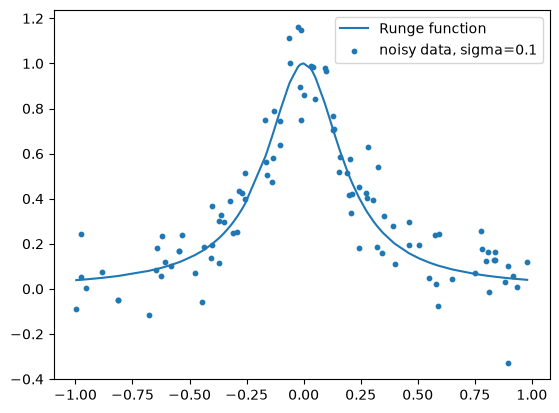

In [6]:
# The data of project 1, as a starting point for part b)
np.random.seed(2026)

def runge(x):
    return 1.0 / (1.0 + 25.0 * x**2)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100 # 350 in Project 1
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1 # 0.25 in Project 1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
Y = y.reshape(-1, 1)  # make y a column vector for the network
print(X.shape, Y.shape)
plt.plot(x, runge(x), label="Runge function")
plt.scatter(x, y, s=10, label=f"noisy data, sigma={sigma}")
plt.legend(); plt.show()

## Data processing
Creates a design matrice out of input values x of chosen degree and  an array out of targets y.   
Splits the data into training and test data and 
scales the data, if "Split and scale" as Process input.

In [7]:
from sklearn.model_selection import train_test_split

def Data_process(x, y,
    test_size = 0.3, Process=None):
    X = np.asarray(x).reshape(-1, 1) # make X a column vector for the network
    y = np.asarray(y).reshape(-1, 1) # make y a column vector for the network


    if Process == "Split and scale":
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, test_size=test_size, random_state=2026
        )

        # Scale polynomial features, leaving the intercept column unchanged.
        mean = X_train[:, 1:].mean(axis=0)
        std = X_train[:, 1:].std(axis=0)
        std[std == 0] = 1

        X_train[:, 1:] = (X_train[:, 1:] - mean) / std
        X_test[:, 1:] = (X_test[:, 1:] - mean) / std

        # I choose not to scale the target.
        #y_mean = y_train.mean(axis=0)
        #y_train_c = y_train - y_mean

        return X_train, X_test, y_train, y_test #y_train_c, y_test, y_mean
    
    if Process == "Scale":
        mean = X[:, 1:].mean(axis=0) 
        std = X[:, 1:].std(axis=0)
        std[std == 0] = 1
        
        X[:, 1:] = (X[:, 1:] - mean) / std

        # I choose not to scale the target.
        #y_mean = y.mean(axis=0)
        #y_c = y - y_mean
        
        return X, y  #y_c, y_mean

    if Process == None:
        return X, y

## Activation functions and MSE


In [8]:
def sigmoid(z):
    return 1 / (1 + jnp.exp(-z))
def sigmoid_der(z):
    s = sigmoid(z)
    return s*(1 - s)
# Alternatively sigmoid_der = jax.grad(jnp.sum(sigmoid(z)))
# Identity
def identity(z):
    return z

def identity_der(z):
    return np.ones_like(z)

# Defining some activation functions
def ReLU(z):
    return jnp.where(z > 0, z, 0.0)
# Derivative of the ReLU function
def ReLU_der(z):
    return jnp.where(z > 0, 1.0, 0.0)

def mse(predict, target):
    return jnp.mean((predict - target) ** 2)
def mse_der(predict, target): # Derivative of cost function
    return 2*(predict - target)/predict.size # Mean brings a factor of 1/N, derivative brings factor 2
# Alternatively: mse_der = jax.grad(mse(predict, target))

def softmax(z):
    """Eq. (8.75) with the shift of Eq. (5.30): rows are samples, columns classes."""
    e = np.exp(z - np.max(z, axis=1, keepdims=True))
    return e / np.sum(e, axis=1, keepdims=True)

def softmax_vec(z):
    """Compute softmax values for each set of scores in the vector z.
    Use this function when you use the activation function on one vector at a time."""
    e_z = jnp.exp(z - jnp.max(z))
    return e_z / jnp.sum(e_z)

def cross_entropy(predict, target):
    # Classification cost_fun
    return -jnp.mean(
        jnp.sum(target * jnp.log(predict), axis=1)
    )

set_epoch = 100

ACTIVATIONS = {"sigmoid": (sigmoid, sigmoid_der),
               "relu": (ReLU, ReLU_der),
               "identity": (identity, identity_der),
               "softmax": (softmax, None)}


OUTPUT = {"mse": identity, "binary": sigmoid, "softmax": softmax} 

## Neural Network Class: Batched
### LLM Declaration: 
#### NeuralNetwork()
I am using LLM chatgpt GPT-6 Luna for learning about the usage of classes.  
The skeleton is from "Exercisesweek42.ipynb" Exercise 8 of repository MachinelearningUiO. 
I am using this skeleton, along with the solution of exerciseweek42.ipynb, to create the class. 

OpenAI assistance with translating the functions 
into working class functions.
OpenAI help with debugging the jax gradients.
OpenAI help with debugging the compute_gradients.

#### Data_processing()
--> Changed y = np.asarray(y) into y = npasarray(y).reshape(-1,1) to get y into the right shape (n,) - > (n,1) : Why this is so i do not understand, but i do understand that without this change, the code wont work in the feed forward saver as the dimensions of the last layer get off.


### Caution
Gradient methods should by handled outside, by performing
general operations on layer_grad list using functions
or classes seperate from the neural network.  
I still chose to include a short plain gradient descent
method for evolving the gradients, for testing.

In [ ]:
class NeuralNetwork:
    def __init__(
        self,
        network_input_size,
        layer_output_sizes,
        activation_funcs,
        activation_ders,
        cost_fun,
        cost_der,
        seed,
    ):
        self.network_input_size = network_input_size
        self.layer_output_sizes = layer_output_sizes
        self.activation_funcs = activation_funcs
        self.activation_ders = activation_ders 
        self.cost_fun = cost_fun
        self.cost_der = cost_der
        self.rng = np.random.default_rng(seed) # Reproducability
        # create layers = [(W , b)] with random normal weights and biases
        layers = []

        i_size = network_input_size
        for layer_output_size in layer_output_sizes:
            W = self.rng.standard_normal((i_size, layer_output_size)) / np.sqrt(i_size) # dele på sqrt(i_size)? Ja for batched
            b = np.zeros(layer_output_size) + 0.01 #np.random.randn(layer_output_size)
            layers.append((W, b))

            i_size = layer_output_size
        
        self.layers = layers

    def predict(self, inputs):
        # Simple feed forward pass
        a = jnp.asarray(inputs) 
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def cost(self, inputs, targets):
        predictions = self.predict(inputs)
        #print("Prediksjoner:", predictions.shape)
        #print("Fasit:", targets.shape)
        #print("Kostfunksjon:", self.cost_fun.__name__)

        mse = self.cost_fun(predictions,targets)
        return mse

    def _feed_forward_saver(self, inputs):
        layer_inputs = []
        zs = []
        a = jnp.asarray(inputs)
        for (W, b), activation_func in zip(self.layers, self.activation_funcs):
            layer_inputs.append(a)
            #print("a",a.shape)
            #print("W",W.shape)
            #print("b", b.shape)
            z = a @ W + b
            zs.append(z)
            a = activation_func(z)
        return layer_inputs, zs, a 

    def compute_gradient_standard(self, inputs, targets):
        # Backpropagation
        # dC_dW = dC_da @ da_dz @ dz_dW
        # dC_db = dC_da @ da_dz @ dz_db
        layer_inputs, sz, predict = self._feed_forward_saver(
            inputs)
        layer_grads = [() for layer in self.layers]

        for l in reversed(range(len(self.layers))):
            layer_input, z, activation_der = layer_inputs[l], sz[l], self.activation_ders[l]

            if l == (len(self.layers) - 1): # last layer
                dC_da = self.cost_der(predict, targets)
            else:
                (W, b) = self.layers[l + 1]
                #print("layer", l)
                #print("predictions:", predict.shape)
                #print("targets:", targets.shape)
                #print("dC_dz:", dC_dz.shape)
                #print("W:", W.shape)
                dC_da = dC_dz @ (W.T) 

            dC_dz = dC_da * activation_der(z) # Hadamard
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis=0) # what happened here?

            layer_grads[l] = (dC_dW, dC_db)
            #print("layer", l)
            #print("predictions:", predict.shape)
            #print("targets:", targets.shape)
            #print("dC_dz:", dC_dz.shape)
        return layer_grads

    def compute_gradient_softmax(self, inputs, targets):
        "Exercicesweek42.ipynb"
        layer_inputs, sz, predict = self._feed_forward_saver(inputs)
        layer_grads = [None] * len(self.layers) # AI assisted for simplicity GPT LUNA 6.1
        n = inputs.shape[0]

        for l in reversed(range(len(self.layers))):
            layer_input = layer_inputs[l]

            if l == len(self.layers) - 1:
                # Softmax + mean cross entropy
                dC_dz  = (predict - targets)/n
            else:
                (W, b) = self.layers[l + 1] # W_next, b_next
                z = sz[l]
                activation_der = self.activation_ders[l]
                dC_dz = (dC_dz @ W.T) * activation_der(z)
        
            dC_dW = layer_input.T @ dC_dz
            dC_db = np.sum(dC_dz, axis = 0)

            layer_grads[l] = (dC_dW, dC_db)

        return layer_grads

    def compute_gradient(self, inputs, targets):
        "AI Declaration: Created with help of GPT-6.1 Sol for SGD function compute_gradient"
        if self.activation_funcs[-1] is softmax:
            return self.compute_gradient_softmax(inputs, targets)

        return self.compute_gradient_standard(inputs, targets)

    
    def accuracy(self, predictions, targets):
        "Exerciseweek42: Classification"
        one_hot_predictions = np.zeros(predictions.shape)

        for i, prediction in enumerate(predictions):
            one_hot_predictions[i, np.argmax(prediction)] = 1
        return accuracy_score(one_hot_predictions, targets) # ski-kit function

    # These last two methods are not needed in the project, but they can be nice to have!
    # This should be External! But i can try use plain gradient
    # BEWARE: Using this function will change the local variable self.layers in the object
    def update_weights_plain(self, layer_grads, gamma=0.05):
        self.layers = [
        (W - gamma * W_g, b - gamma * b_g)
        for (W, b), (W_g, b_g) in zip(self.layers, layer_grads)]


    # jax solution
    # The first one has a layers parameter so that you can use jax.grad on it.
    
    def jax_compliant_predict(self, layers, inputs):
        a = jnp.asarray(inputs)

        for (W, b), activation_func in zip(layers, self.activation_funcs):
            z = a @ W + b
            a = activation_func(z)
        return a

    def jax_cost(self, layers, inputs, targets):
        predictions = self.jax_compliant_predict(layers, inputs)
        mse = self.cost_fun(predictions, targets)
        return mse

    def jax_gradient(self, inputs, targets):
        grads = jax.grad(self.jax_cost,argnums = 0)(self.layers, inputs, targets)
        return grads

## Class Optimizer

In [10]:
class Optimizer:
    """Oppdaterer nettverkslag med plain gradient descent, Adam eller RMSprop."""

    def __init__(
        self, method, gamma,
        beta1=0.9, beta2=0.999, rho=0.99, eps=1e-8
    ):
        self.method = method.lower()
        self.gamma = gamma
        self.beta1 = beta1
        self.beta2 = beta2
        self.rho = rho
        self.eps = eps

        self.state = None
        self.t = 0

    def zero_state(self, layers):
        """Lag nullstilte momentverdier for Adam og RMSprop."""
        return [
            (
                np.zeros_like(W),  # mW
                np.zeros_like(b),  # mb
                np.zeros_like(W),  # vW
                np.zeros_like(b),  # vb
            )
            for W, b in layers
        ]

    def initialize(self, layers):
        """Start en ny treningskjøring."""
        self.t = 0

        if self.method == "plain":
            self.state = None
        else:
            self.state = self.zero_state(layers)

    def step(self, layers, layer_grads, gamma=None):
        """Utfør én minibatchoppdatering."""
        if gamma is None:
            gamma = self.gamma

        self.t += 1

        if self.method == "plain":
            return self.step_plain(layers, layer_grads, gamma)

        if self.state is None:
            raise RuntimeError("Kjør optimizer.initialize(layers) før trening.")

        if self.method == "adam":
            return self.step_adam(layers, layer_grads, gamma)

        if self.method == "rmsprop":
            return self.step_rmsprop(layers, layer_grads, gamma)

        raise ValueError("method må være 'plain', 'adam' eller 'rmsprop'")

    def step_plain(self, layers, layer_grads, gamma):
        return [
            (W - gamma * dW, b - gamma * db)
            for (W, b), (dW, db) in zip(layers, layer_grads)
        ]

    def step_rmsprop(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            vW = self.rho * vW + (1 - self.rho) * dW**2
            vb = self.rho * vb + (1 - self.rho) * db**2

            W = W - gamma * dW / (np.sqrt(vW) + self.eps)
            b = b - gamma * db / (np.sqrt(vb) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

    def step_adam(self, layers, layer_grads, gamma):
        new_layers = []
        new_state = []

        for (W, b), (dW, db), (mW, mb, vW, vb) in zip(
            layers, layer_grads, self.state
        ):
            dW = np.asarray(dW)
            db = np.asarray(db)

            mW = self.beta1 * mW + (1 - self.beta1) * dW
            mb = self.beta1 * mb + (1 - self.beta1) * db
            vW = self.beta2 * vW + (1 - self.beta2) * dW**2
            vb = self.beta2 * vb + (1 - self.beta2) * db**2

            mW_hat = mW / (1 - self.beta1**self.t)
            mb_hat = mb / (1 - self.beta1**self.t)
            vW_hat = vW / (1 - self.beta2**self.t)
            vb_hat = vb / (1 - self.beta2**self.t)

            W = W - gamma * mW_hat / (np.sqrt(vW_hat) + self.eps)
            b = b - gamma * mb_hat / (np.sqrt(vb_hat) + self.eps)

            new_layers.append((W, b))
            new_state.append((mW, mb, vW, vb))

        self.state = new_state
        return new_layers

## Func SGD Train

In [11]:
def step_length(t, t0, t1):
    """A decaying learning-rate schedule."""
    return t0 / (t + t1)

def train_sgd(
    network, X, y, method="adam",
    epochs=set_epoch, batch_size=5, gamma=0.001, lmb = 0.0, penalty ="l2", schedule=None, seed=2026
):
    "LLM Assisted: Using the class netowrk"
    rng = np.random.default_rng(seed)

    X = np.asarray(X)
    y = np.asarray(y) #.reshape(-1, 1)

    # Bruk av klasse
    optimizer = Optimizer(method=method, gamma=gamma)
    optimizer.initialize(network.layers)

    # Tilstanden er en liste med tupler, ett for hvert lag.
    state = None if method == "plain" else optimizer.zero_state(network.layers)
    t = 0
    history = []
    history_test = []
    
    for epoch in range(epochs):
        # Bland rekkefølgen på datapunktene for hver epoke.
        indices = rng.permutation(len(X))
        # Minibatch
        for start in range(0, len(X), batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X[batch]
            y_batch = y[batch]

            # Hent gradientene fra nettverksobjektet.
            layer_grads = network.compute_gradient(X_batch, y_batch)

            #L2 norm - Ridge
            "AI Declaration: Help from codex GPT-LUNA6.1 for task 2b) L1 and L2 placement"
            if penalty == "l2":
                layer_grads = [
                (dW + 2 * lmb * W, db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)]
            #L1 norm - Lasso
            #"AI Declaration: Help from codex GPT-Luna6.1"
            elif penalty == "l1":
                layer_grads = [
                (dW + lmb * np.sign(W), db)
                for (W, b), (dW, db) in zip(network.layers, layer_grads)
                ]
            elif penalty is not None:
                raise ValueError("penalty må være 'l1', 'l2' eller None")

            # Tell minibatchoppdateringer. Adam bruker t til korreksjon
            # for oppstartsfasen.
            t += 1
            gamma = gamma if schedule is None else step_length(t - 1, *schedule)
            network.layers = optimizer.step(network.layers, layer_grads)

        # Kostnaden etter at hele treningssettet har vært gjennom én gang.
        epoch_cost = float(network.cost(X, y))
        history.append(epoch_cost)
    

    return history, network.layers

## Func PGD train

In [12]:
def train_plain(
    network, X, y, gamma=0.001, lmb = 0.0, penalty = None, epochs=set_epoch, seed = 2026
    ):
    rng = np.random.default_rng(seed)
    inputs = np.asarray(X)
    targets = np.asarray(y)
    
    optimizer = Optimizer(method="plain", gamma=gamma)
    optimizer.initialize(network.layers)
    state = None
    history = []
    

    for i in range(epochs):
        layer_grads = network.compute_gradient(inputs, targets)
        
        "Cope from SGD_train()"
        if penalty == "l2":
            layer_grads = [
            (dW + 2 * lmb * W, db)
            for (W, b), (dW, db) in zip(network.layers, layer_grads)]
        elif penalty == "l1":
            layer_grads = [
            (dW + lmb * np.sign(W), db)
            for (W, b), (dW, db) in zip(network.layers, layer_grads)
            ]
        elif penalty is not None:
            raise ValueError("penalty må være 'l1', 'l2' eller None")
        
        network.layers = optimizer.step(network.layers, layer_grads)
        
        cost = float(network.cost(inputs, targets))
        history.append((cost))
            

    return history, network.layers

## NeuralNetRegressor

In [13]:
class NeuralNetRegressor(BaseEstimator, RegressorMixin):
    """Your Project 2 network with the scikit-learn estimator interface."""
    "OBS: This class is outdated and will be replaced by a new version with more features and better structure."
    "This is not done yet since the fit() method is not fully implemented. It is a work in progress."
    def __init__(self, 
    hidden=(50,), activation="sigmoid", 
    gamma=0.01, lmbd=0.0, 
    penalty=None, method = "plain", 
    epochs=set_epoch, batch_size=10, seed=2026):
        # store the hyperparameters under the same names; no computation here
        self.hidden = hidden
        self.activation = activation
        self.gamma = gamma
        self.lmbd = lmbd
        self.penalty = penalty
        self.method = method
        self.epochs = epochs
        self.batch_size = batch_size
        self.seed = seed

    def fit(self, X, y, m_descent = "sgd"):
        # X has shape (n, 1), y shape (n,): build the layers from self.seed,
        # train with your SGD for self.epochs epochs, store the layers in self.layers_

        """LLM Assistance: Creating the activation funcs in correct format"""
        hidden_func, hidden_der = ACTIVATIONS[self.activation]
        activation_funcs = [hidden_func] * len(self.hidden) + [identity]
        activation_ders = [hidden_der] * len(self.hidden) + [identity_der]

        self.network_ = NeuralNetwork(
            network_input_size=X.shape[1],
            layer_output_sizes=(*self.hidden,1), # LLM Assisted - Shape error
            activation_funcs= activation_funcs,
            activation_ders = activation_ders,
            cost_fun=mse,
            cost_der=mse_der,
            seed=self.seed
        )

        if m_descent == "sgd":
            self.history, self.layer = train_sgd(self.network_, X, y, method = self.method,
                                epochs = self.epochs, batch_size = self.batch_size, 
                                gamma = self.gamma, lmb = self.lmbd, penalty=self.penalty, seed = self.seed)
        elif m_descent == "plain":
            self.history, self.layer = train_plain(self.network_, X, y, gamma = self.gamma, lmb = self.lmbd, penalty=self.penalty, epochs = self.epochs, seed = self.seed)
        else:
            raise ValueError("m_descent must be 'sgd' or 'plain'")
        return self

    def predict(self, X):
        """LM Assisted: Use of class functionality
           LM Assisted: Reshaping of output array to 1D for Scikit""" 
        # the network output as a 1D array of length len(X)
        predictions = self.network_.predict(X)
        predictions_1D = np.asarray(predictions).reshape(-1)
        return predictions_1D

## One hidden layer, 50 nodes with Sigmoid in hidden layer
### Kontroller gradientberegning mot Jax i NeuralNetwork
### Check the Regressor against regular method for SGD and PGD

In [74]:
"Stochastic Gradient Descent with mini-batches"
for method in ["plain", "adam", "rmsprop"]:
    print(f"Training with {method} method")
    # Manual Method
    network_input_size = X.shape[-1] # 9
    network_output_size = 1 # same order as y
    layer_output_sizes = [50, 1]
    activation_funcs=[sigmoid, identity]
    activation_ders=[sigmoid_der, identity_der]
    cost_fun=mse
    cost_der=mse_der

    NN = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes,
        activation_funcs=activation_funcs,
        activation_ders=activation_ders,
        cost_fun=mse,
        cost_der=mse_der,
        seed = 2026
    )

    history, last_layers = train_sgd(NN, X, Y, method=method, epochs=set_epoch, 
    batch_size=10, gamma=0.01, lmb = 0.0, penalty =None, schedule=None, seed=2026)
    MSE_SGD_M = history[-1]

    "Gradient Calculation"
    gradients = NN.compute_gradient(X, Y)
    jax_grad = NN.jax_gradient(X, Y)

    print("The gradients agree with jax.grad:", [(np.allclose(dW, dW_j), np.allclose(db, db_j))
                                    for (dW, db), (dW_j, db_j) in zip(gradients, jax_grad)])


    # Regressor
    NN_R = NeuralNetRegressor(hidden=(50,), activation="sigmoid", 
    gamma=0.01, lmbd=0.0, penalty=None, method=method, epochs=set_epoch, batch_size=10, seed=2026)
    NN_R.fit(X, Y, m_descent = "sgd")
    prediction_R = NN_R.predict(X)
    MSE_SGD = mse(prediction_R, Y.ravel()) # reshape to 1D for MSE calculation
            
    print(
        "SGD: The methods agree to numerical precision:",
        np.allclose(MSE_SGD, MSE_SGD_M)
    )

    "Plain Gradient Descent"
    # NeuralNetwork with plain gradient descent
    NN_p = NeuralNetwork(
        network_input_size=network_input_size,
        layer_output_sizes=layer_output_sizes,
        activation_funcs=activation_funcs,
        activation_ders=activation_ders,
        cost_fun=mse,
        cost_der=mse_der,
        seed = 2026
    )
    histroy_plain, last_layers_plain = train_plain(NN_p, X, Y, gamma=0.01, lmb = 0.0, penalty ="l2", epochs=set_epoch, seed=2026)
    mse_plain = histroy_plain[-1]

    # Regressor with plain gradient descent
    NN_R_plain = NeuralNetRegressor(hidden=(50,), activation="sigmoid",
    gamma=0.01, lmbd=0.0, penalty=None, method=method, epochs=set_epoch, batch_size=10, seed=2026)
    NN_R_plain.fit(X, Y, m_descent = "plain")
    prediction_R_plain = NN_R_plain.predict(X)
    mse_R_plain = mse(prediction_R_plain, Y.ravel())

    print(
        "PGD: The methods agree to numerical precision:",
        np.allclose(mse_R_plain, mse_plain)
    )  

    print("MSE SGD:", MSE_SGD, "MSE PGD:", mse_R_plain)

Training with plain method
The gradients agree with jax.grad: [(True, True), (True, True)]
SGD: The methods agree to numerical precision: True
PGD: The methods agree to numerical precision: True
MSE SGD: 0.15603659870538986 MSE PGD: 0.15849019404312506
Training with adam method
The gradients agree with jax.grad: [(True, True), (True, True)]
SGD: The methods agree to numerical precision: True
PGD: The methods agree to numerical precision: True
MSE SGD: 0.07020435415022384 MSE PGD: 0.15849019404312506
Training with rmsprop method
The gradients agree with jax.grad: [(True, True), (True, True)]
SGD: The methods agree to numerical precision: True
PGD: The methods agree to numerical precision: True
MSE SGD: 0.0857507938928996 MSE PGD: 0.15849019404312506


## Two hidden layer with sigmoid, 50 and 100 nodes. 


AI Declaration: This section is generated with help of Copilot, as it is a copy of the code cell above.

In [75]:
for method in ["plain", "adam", "rmsprop"]:
    print(f"Training with {method} method for 2 hidden layers")
    # Manual Method
    network_input_size2 = X.shape[-1] # 9
    network_output_size2 = 1 # same order as y
    layer_output_sizes2 = [50, 100, 1]
    activation_funcs2=[sigmoid, sigmoid, identity]
    activation_ders2=[sigmoid_der, sigmoid_der, identity_der]
    cost_fun2=mse
    cost_der2=mse_der

    NN_2 = NeuralNetwork(
        network_input_size=network_input_size2,
        layer_output_sizes=layer_output_sizes2,
        activation_funcs=activation_funcs2,
        activation_ders=activation_ders2,
        cost_fun=cost_fun2,
        cost_der=cost_der2,
        seed = 2026
    )
    history_2, last_layers_2 = train_sgd(NN_2, X, Y, method=method, epochs=set_epoch, 
    batch_size=10, gamma=0.01, lmb = 0.0, penalty =None, schedule=None, seed=2026)
    MSE_SGD_M_2 = history_2[-1]


    NN_R_2 = NeuralNetRegressor(hidden=(50,100,), activation="sigmoid",
    gamma=0.01, lmbd=0.0, penalty=None, method=method, epochs=set_epoch, batch_size=10, seed=2026)
    NN_R_2.fit(X, Y, m_descent = "sgd")
    mse_R_2 = mse(NN_R_2.predict(X), Y.ravel())

    print(
        "SGD: The methods agree to numerical precision:",
        np.allclose(mse_R_2, MSE_SGD_M_2)
    )

    #Plain Gradient Descent with 2 hidden layers
    NN_p_2 = NeuralNetwork(
        network_input_size=network_input_size2,
        layer_output_sizes=layer_output_sizes2,
        activation_funcs=activation_funcs2,
        activation_ders=activation_ders2,
        cost_fun=cost_fun2,
        cost_der=cost_der2,
        seed = 2026
    )
    history_plain_2, last_layers_plain_2 = train_plain(NN_p_2, X, Y, gamma=0.01, lmb = 0.0, penalty ="l2", epochs=set_epoch, seed=2026)
    mse_plain_2 = history_plain_2[-1]   

    NN_R_plain_2 = NeuralNetRegressor(hidden=(50,100,), activation="sigmoid",
    gamma=0.01, lmbd=0.0, penalty=None, method=method, epochs=set_epoch, batch_size=10, seed=2026)
    NN_R_plain_2.fit(X, Y, m_descent = "plain")
    mse_R_plain_2 = mse(NN_R_plain_2.predict(X), Y.ravel())

    print(
        "PGD: The methods agree to numerical precision:",
        np.allclose(mse_R_plain_2, mse_plain_2)
    )
    print("MSE SGD 2 hidden layers:", mse_R_2, "MSE PGD 2 hidden layers:", mse_R_plain_2)

Training with plain method for 2 hidden layers
SGD: The methods agree to numerical precision: True
PGD: The methods agree to numerical precision: True
MSE SGD 2 hidden layers: 0.16002744147727302 MSE PGD 2 hidden layers: 0.1585433990679542
Training with adam method for 2 hidden layers
SGD: The methods agree to numerical precision: True
PGD: The methods agree to numerical precision: True
MSE SGD 2 hidden layers: 0.06904853439568084 MSE PGD 2 hidden layers: 0.1585433990679542
Training with rmsprop method for 2 hidden layers
SGD: The methods agree to numerical precision: True
PGD: The methods agree to numerical precision: True
MSE SGD 2 hidden layers: 0.0704183778100171 MSE PGD 2 hidden layers: 0.1585433990679542
